<a href="https://colab.research.google.com/github/sirinsultana741140-lgtm/phishing-website-detection/blob/main/Phishing_Website_Detection.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [88]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

import joblib

from sklearn.model_selection import (
    train_test_split,
    cross_val_score,
    GridSearchCV,
    StratifiedKFold
)

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)

import warnings
warnings.filterwarnings("ignore")

print("All libraries imported successfully!")

All libraries imported successfully!


Load Dataset

In [89]:
import pandas as pd
import zipfile
import os
from google.colab import drive

# Mount Google Drive to access your files
drive.mount('/content/drive')

# Extract the zip file to access the dataset
zip_file_path = '/content/drive/MyDrive/archive (2).zip'

if os.path.exists(zip_file_path):
    with zipfile.ZipFile(zip_file_path, 'r') as zip_ref:
        zip_ref.extractall('/content/')

    # List files to verify the correct filename and path
    extracted_files = os.listdir('/content/')
    print("Extracted files:", extracted_files)

    # Load the dataset now that it has been extracted
    df = pd.read_csv('/content/dataset.csv')
    print("Dataset loaded successfully!")
    display(df.head())
else:
    print(f"Error: The file '{zip_file_path}' was not found. Please verify that the file exists in your Google Drive and that the path is spelled correctly.")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Extracted files: ['.config', 'phishing_detection_model.pkl', 'new_website_data.csv', 'drive', 'dataset.csv', 'prediction_results.csv', 'sample_data']
Dataset loaded successfully!


,index,having_IPhaving_IP_Address,URLURL_Length,Shortining_Service,having_At_Symbol,double_slash_redirecting,Prefix_Suffix,having_Sub_Domain,SSLfinal_State,Domain_registeration_length,...,popUpWidnow,Iframe,age_of_domain,DNSRecord,web_traffic,Page_Rank,Google_Index,Links_pointing_to_page,Statistical_report,Result
0,1,-1,1,1,1,-1,-1,-1,-1,-1,...,1,1,-1,-1,-1,-1,1,1,-1,-1
1,2,1,1,1,1,1,-1,0,1,-1,...,1,1,-1,-1,0,-1,1,1,1,-1
2,3,1,0,1,1,1,-1,-1,-1,-1,...,1,1,1,-1,1,-1,1,0,-1,-1
3,4,1,0,1,1,1,-1,-1,-1,1,...,1,1,-1,-1,1,-1,1,-1,1,-1
4,5,1,0,-1,1,1,-1,1,1,-1,...,-1,1,-1,-1,0,-1,1,1,1,1


In [ ]:
df.head()

,index,having_IPhaving_IP_Address,URLURL_Length,Shortining_Service,having_At_Symbol,double_slash_redirecting,Prefix_Suffix,having_Sub_Domain,SSLfinal_State,Domain_registeration_length,...,popUpWidnow,Iframe,age_of_domain,DNSRecord,web_traffic,Page_Rank,Google_Index,Links_pointing_to_page,Statistical_report,Result
0,1,-1,1,1,1,-1,-1,-1,-1,-1,...,1,1,-1,-1,-1,-1,1,1,-1,-1
1,2,1,1,1,1,1,-1,0,1,-1,...,1,1,-1,-1,0,-1,1,1,1,-1
2,3,1,0,1,1,1,-1,-1,-1,-1,...,1,1,1,-1,1,-1,1,0,-1,-1
3,4,1,0,1,1,1,-1,-1,-1,1,...,1,1,-1,-1,1,-1,1,-1,1,-1
4,5,1,0,-1,1,1,-1,1,1,-1,...,-1,1,-1,-1,0,-1,1,1,1,1


In [ ]:
df.head()
df.tail()
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 11055 entries, 0 to 11054
Data columns (total 32 columns):
 #   Column                       Non-Null Count  Dtype
---  ------                       --------------  -----
 0   index                        11055 non-null  int64
 1   having_IPhaving_IP_Address   11055 non-null  int64
 2   URLURL_Length                11055 non-null  int64
 3   Shortining_Service           11055 non-null  int64
 4   having_At_Symbol             11055 non-null  int64
 5   double_slash_redirecting     11055 non-null  int64
 6   Prefix_Suffix                11055 non-null  int64
 7   having_Sub_Domain            11055 non-null  int64
 8   SSLfinal_State               11055 non-null  int64
 9   Domain_registeration_length  11055 non-null  int64
 10  Favicon                      11055 non-null  int64
 11  port                         11055 non-null  int64
 12  HTTPS_token                  11055 non-null  int64
 13  Request_URL                  11055 non-null  i

In [ ]:
df.tail()

,index,having_IPhaving_IP_Address,URLURL_Length,Shortining_Service,having_At_Symbol,double_slash_redirecting,Prefix_Suffix,having_Sub_Domain,SSLfinal_State,Domain_registeration_length,...,popUpWidnow,Iframe,age_of_domain,DNSRecord,web_traffic,Page_Rank,Google_Index,Links_pointing_to_page,Statistical_report,Result
11050,11051,1,-1,1,-1,1,1,1,1,-1,...,-1,-1,1,1,-1,-1,1,1,1,1
11051,11052,-1,1,1,-1,-1,-1,1,-1,-1,...,-1,1,1,1,1,1,1,-1,1,-1
11052,11053,1,-1,1,1,1,-1,1,-1,-1,...,1,1,1,1,1,-1,1,0,1,-1
11053,11054,-1,-1,1,1,1,-1,-1,-1,1,...,-1,1,1,1,1,-1,1,1,1,-1
11054,11055,-1,-1,1,1,1,-1,-1,-1,1,...,1,1,-1,1,-1,-1,-1,1,-1,-1


In [ ]:
print(df.shape)

(11055, 32)


In [ ]:
print(df.columns)

Index(['index', 'having_IPhaving_IP_Address', 'URLURL_Length',
       'Shortining_Service', 'having_At_Symbol', 'double_slash_redirecting',
       'Prefix_Suffix', 'having_Sub_Domain', 'SSLfinal_State',
       'Domain_registeration_length', 'Favicon', 'port', 'HTTPS_token',
       'Request_URL', 'URL_of_Anchor', 'Links_in_tags', 'SFH',
       'Submitting_to_email', 'Abnormal_URL', 'Redirect', 'on_mouseover',
       'RightClick', 'popUpWidnow', 'Iframe', 'age_of_domain', 'DNSRecord',
       'web_traffic', 'Page_Rank', 'Google_Index', 'Links_pointing_to_page',
       'Statistical_report', 'Result'],
      dtype='object')


In [ ]:
print(df.dtypes)

index                          int64
having_IPhaving_IP_Address     int64
URLURL_Length                  int64
Shortining_Service             int64
having_At_Symbol               int64
double_slash_redirecting       int64
Prefix_Suffix                  int64
having_Sub_Domain              int64
SSLfinal_State                 int64
Domain_registeration_length    int64
Favicon                        int64
port                           int64
HTTPS_token                    int64
Request_URL                    int64
URL_of_Anchor                  int64
Links_in_tags                  int64
SFH                            int64
Submitting_to_email            int64
Abnormal_URL                   int64
Redirect                       int64
on_mouseover                   int64
RightClick                     int64
popUpWidnow                    int64
Iframe                         int64
age_of_domain                  int64
DNSRecord                      int64
web_traffic                    int64
P

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 11055 entries, 0 to 11054
Data columns (total 32 columns):
 #   Column                       Non-Null Count  Dtype
---  ------                       --------------  -----
 0   index                        11055 non-null  int64
 1   having_IPhaving_IP_Address   11055 non-null  int64
 2   URLURL_Length                11055 non-null  int64
 3   Shortining_Service           11055 non-null  int64
 4   having_At_Symbol             11055 non-null  int64
 5   double_slash_redirecting     11055 non-null  int64
 6   Prefix_Suffix                11055 non-null  int64
 7   having_Sub_Domain            11055 non-null  int64
 8   SSLfinal_State               11055 non-null  int64
 9   Domain_registeration_length  11055 non-null  int64
 10  Favicon                      11055 non-null  int64
 11  port                         11055 non-null  int64
 12  HTTPS_token                  11055 non-null  int64
 13  Request_URL                  11055 non-null  i

In [ ]:
df.describe()

,index,having_IPhaving_IP_Address,URLURL_Length,Shortining_Service,having_At_Symbol,double_slash_redirecting,Prefix_Suffix,having_Sub_Domain,SSLfinal_State,Domain_registeration_length,...,popUpWidnow,Iframe,age_of_domain,DNSRecord,web_traffic,Page_Rank,Google_Index,Links_pointing_to_page,Statistical_report,Result
count,11055.000000,11055.000000,11055.000000,11055.000000,11055.000000,11055.000000,11055.000000,11055.000000,11055.000000,11055.000000,...,11055.000000,11055.000000,11055.000000,11055.000000,11055.000000,11055.000000,11055.000000,11055.000000,11055.000000,11055.000000
mean,5528.000000,0.313795,-0.633198,0.738761,0.700588,0.741474,-0.734962,0.063953,0.250927,-0.336771,...,0.613388,0.816915,0.061239,0.377114,0.287291,-0.483673,0.721574,0.344007,0.719584,0.113885
std,3191.447947,0.949534,0.766095,0.673998,0.713598,0.671011,0.678139,0.817518,0.911892,0.941629,...,0.789818,0.576784,0.998168,0.926209,0.827733,0.875289,0.692369,0.569944,0.694437,0.993539
min,1.000000,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,...,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000
25%,2764.500000,-1.000000,-1.000000,1.000000,1.000000,1.000000,-1.000000,-1.000000,-1.000000,-1.000000,...,1.000000,1.000000,-1.000000,-1.000000,0.000000,-1.000000,1.000000,0.000000,1.000000,-1.000000
50%,5528.000000,1.000000,-1.000000,1.000000,1.000000,1.000000,-1.000000,0.000000,1.000000,-1.000000,...,1.000000,1.000000,1.000000,1.000000,1.000000,-1.000000,1.000000,0.000000,1.000000,1.000000
75%,8291.500000,1.000000,-1.000000,1.000000,1.000000,1.000000,-1.000000,1.000000,1.000000,1.000000,...,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000
max,11055.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,...,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


In [ ]:
print(df.describe(include="all"))

              index  having_IPhaving_IP_Address  URLURL_Length  \
count  11055.000000                11055.000000   11055.000000   
mean    5528.000000                    0.313795      -0.633198   
std     3191.447947                    0.949534       0.766095   
min        1.000000                   -1.000000      -1.000000   
25%     2764.500000                   -1.000000      -1.000000   
50%     5528.000000                    1.000000      -1.000000   
75%     8291.500000                    1.000000      -1.000000   
max    11055.000000                    1.000000       1.000000   

       Shortining_Service  having_At_Symbol  double_slash_redirecting  \
count        11055.000000      11055.000000              11055.000000   
mean             0.738761          0.700588                  0.741474   
std              0.673998          0.713598                  0.671011   
min             -1.000000         -1.000000                 -1.000000   
25%              1.000000          1.000

In [ ]:
df = df.loc[:, ~df.columns.astype(str).str.startswith("Unnamed:")]


In [ ]:
possible_targets = ["Result", "result", "class", "Class", "target", "Target"]

target_col = next(
    (col for col in possible_targets if col in df.columns),
    df.columns[-1]
)

print("Target Column:", target_col)




Target Column: Result


In [ ]:
df = df.dropna(subset=[target_col]).copy()

In [ ]:
print("\nOriginal Target Values:")
print(df[target_col].value_counts())


Original Target Values:
Result
 1    6157
-1    4898
Name: count, dtype: int64


In [ ]:
def convert_target(value):

    value = str(value).strip().lower()

    # UCI dataset encoding
    if value in ["-1", "phishing", "phish"]:
        return 1

    if value in ["1", "legitimate", "legit", "safe"]:
        return 0

    if value in ["0"]:
        return 0

    raise ValueError(f"Unknown target label: {value}")


df[target_col] = df[target_col].apply(convert_target)

print("Target converted successfully!")

print("\n0 = Legitimate")
print("1 = Phishing")

print(df[target_col].value_counts())

Target converted successfully!

0 = Legitimate
1 = Phishing
Result
0    6157
1    4898
Name: count, dtype: int64


In [ ]:
print("Missing Values:")

print(df.isnull().sum())

print("\nTotal Missing Values:")

print(df.isnull().sum().sum())

Missing Values:
index                          0
having_IPhaving_IP_Address     0
URLURL_Length                  0
Shortining_Service             0
having_At_Symbol               0
double_slash_redirecting       0
Prefix_Suffix                  0
having_Sub_Domain              0
SSLfinal_State                 0
Domain_registeration_length    0
Favicon                        0
port                           0
HTTPS_token                    0
Request_URL                    0
URL_of_Anchor                  0
Links_in_tags                  0
SFH                            0
Submitting_to_email            0
Abnormal_URL                   0
Redirect                       0
on_mouseover                   0
RightClick                     0
popUpWidnow                    0
Iframe                         0
age_of_domain                  0
DNSRecord                      0
web_traffic                    0
Page_Rank                      0
Google_Index                   0
Links_pointing_to_page     

In [ ]:
print("Duplicate Records:")

print(df.duplicated().sum())

# Remove duplicate records
df = df.drop_duplicates().reset_index(drop=True)

print("\nShape After Removing Duplicates:")

print(df.shape)

Duplicate Records:
0

Shape After Removing Duplicates:
(11055, 32)


In [ ]:
class_counts = df[target_col].value_counts().sort_index()

print("Website Classification:")

print(class_counts)

print("\n0 = Legitimate")
print("1 = Phishing")

Website Classification:
Result
0    6157
1    4898
Name: count, dtype: int64

0 = Legitimate
1 = Phishing


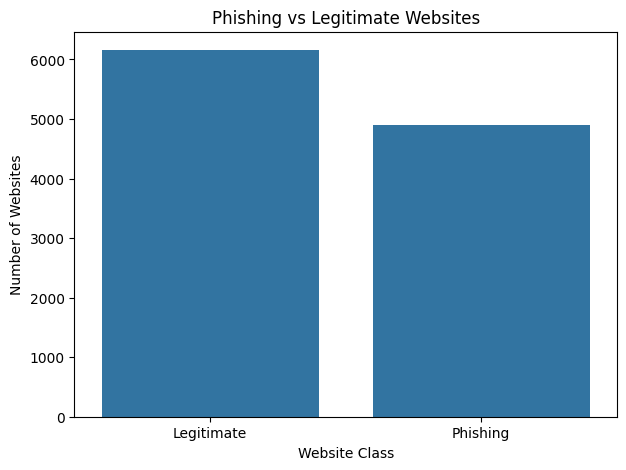

In [ ]:
plt.figure(figsize=(7, 5))

sns.countplot(
    x=target_col,
    data=df
)

plt.title("Phishing vs Legitimate Websites")

plt.xlabel("Website Class")

plt.ylabel("Number of Websites")

plt.xticks([0, 1], ["Legitimate", "Phishing"])

plt.show()

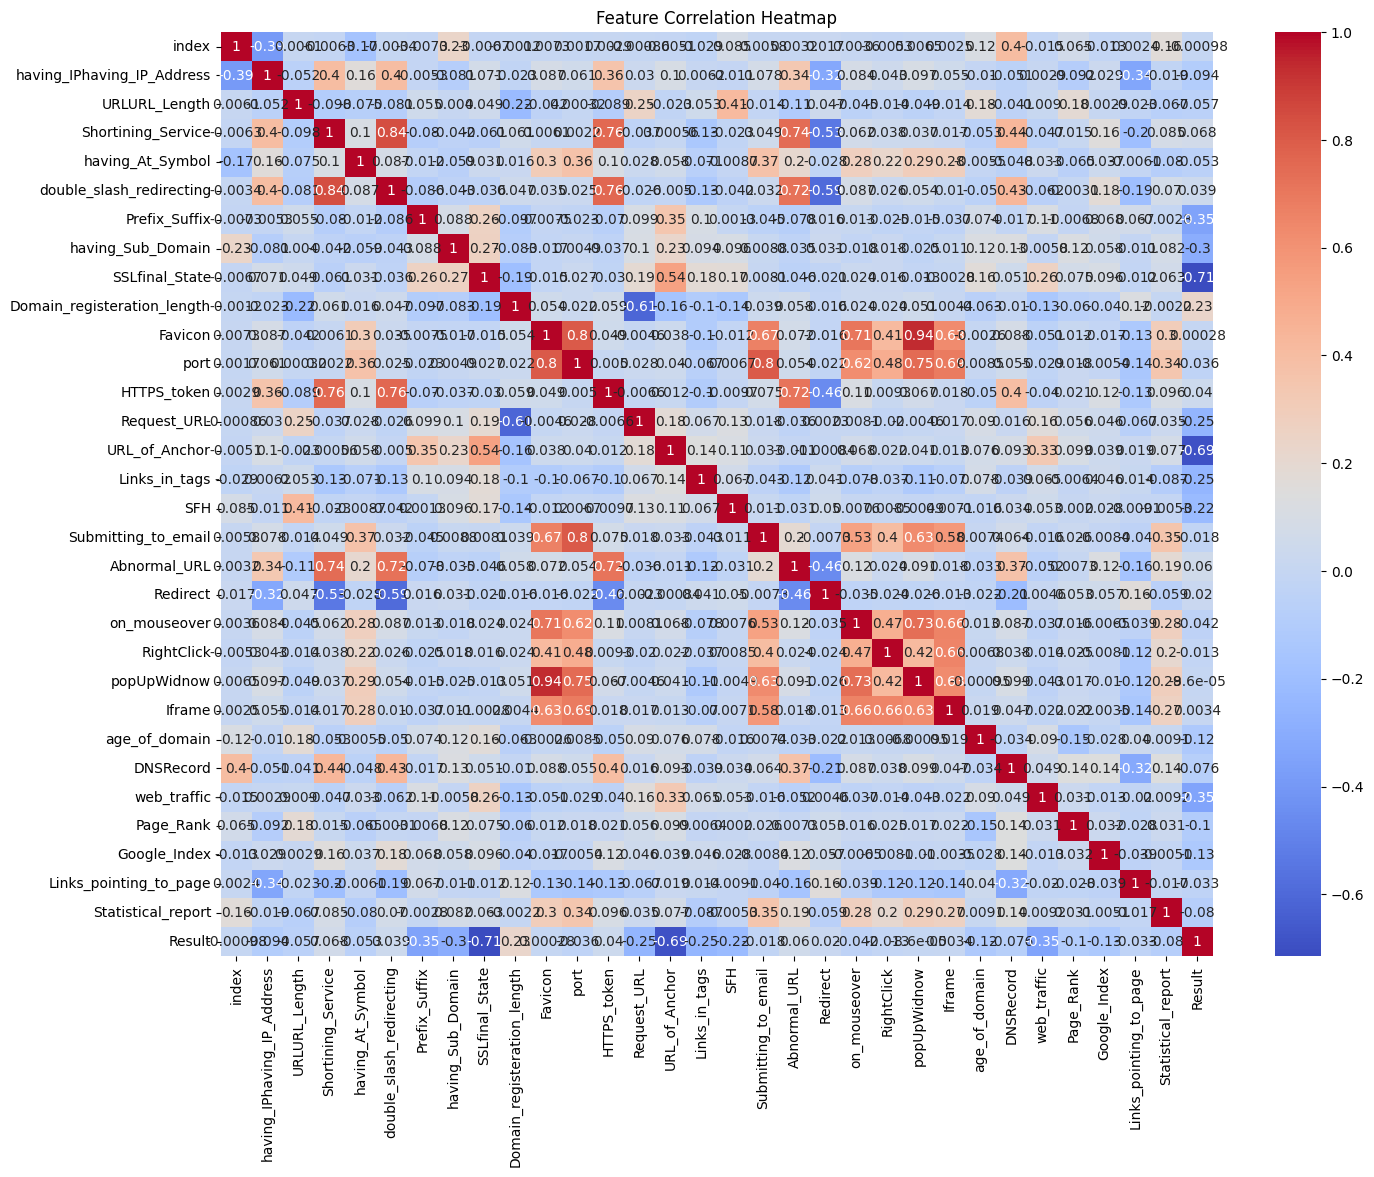

In [ ]:
numeric_df = df.select_dtypes(include=np.number)

plt.figure(figsize=(16, 12))

sns.heatmap(
    numeric_df.corr(),
    cmap="coolwarm",
    annot=True
)

plt.title("Feature Correlation Heatmap")

plt.show()

In [ ]:
X = df.drop(columns=[target_col])

y = df[target_col]

print("Input Features Shape:", X.shape)

print("Target Shape:", y.shape)

print("\nInput Features:")
print(X.head())

print("\nTarget Values:")
print(y.head())

Input Features Shape: (11055, 31)
Target Shape: (11055,)

Input Features:
   index  having_IPhaving_IP_Address  URLURL_Length  Shortining_Service  \
0      1                          -1              1                   1   
1      2                           1              1                   1   
2      3                           1              0                   1   
3      4                           1              0                   1   
4      5                           1              0                  -1   

   having_At_Symbol  double_slash_redirecting  Prefix_Suffix  \
0                 1                        -1             -1   
1                 1                         1             -1   
2                 1                         1             -1   
3                 1                         1             -1   
4                 1                         1             -1   

   having_Sub_Domain  SSLfinal_State  Domain_registeration_length  ...  \
0               

Identify numerical and categorical columns

In [ ]:
numeric_features = X.select_dtypes(
    include=np.number
).columns.tolist()

categorical_features = X.select_dtypes(
    exclude=np.number
).columns.tolist()

print("Numerical Features:", len(numeric_features))

print("Categorical Features:", len(categorical_features))

Numerical Features: 31
Categorical Features: 0


Create preprocessing pipeline

In [ ]:
# Numerical preprocessing
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine preprocessing
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

print("Preprocessing pipeline created successfully!")

Preprocessing pipeline created successfully!


Split the dataset into training and testing

Train-test split

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training Data:", X_train.shape)

print("Testing Data:", X_test.shape)

print("\nTraining Target Distribution:")

print(y_train.value_counts())

print("\nTesting Target Distribution:")

print(y_test.value_counts())

Training Data: (8844, 31)
Testing Data: (2211, 31)

Training Target Distribution:
Result
0    4926
1    3918
Name: count, dtype: int64

Testing Target Distribution:
Result
0    1231
1     980
Name: count, dtype: int64


Train three machine learning models

Train Logistic Regression

In [ ]:
lr_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=2000,
        random_state=42
    ))
])

lr_model.fit(X_train, y_train)

print("Logistic Regression Training Completed!")

Logistic Regression Training Completed!


In [ ]:
dt_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", DecisionTreeClassifier(
        random_state=42
    ))
])

dt_model.fit(X_train, y_train)

print("Decision Tree Training Completed!")

Decision Tree Training Completed!


In [ ]:
rf_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ))
])

rf_model.fit(X_train, y_train)

print("Random Forest Training Completed!")

Random Forest Training Completed!


Compare model performance



In [ ]:
models = {
    "Logistic Regression": lr_model,
    "Decision Tree": dt_model,
    "Random Forest": rf_model
}

results = []

for name, model in models.items():

    y_pred = model.predict(X_test)

    accuracy = accuracy_score(y_test, y_pred)

    precision = precision_score(
        y_test, y_pred, zero_division=0
    )

    recall = recall_score(
        y_test, y_pred, zero_division=0
    )

    f1 = f1_score(
        y_test, y_pred, zero_division=0
    )

    results.append({
        "Model": name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1
    })

comparison_df = pd.DataFrame(results)

print("MODEL PERFORMANCE COMPARISON")

display(
    comparison_df.round(4)
)

MODEL PERFORMANCE COMPARISON


,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.9281,0.9344,0.9010,0.9174
1,Decision Tree,0.9534,0.9470,0.9480,0.9475
2,Random Forest,0.9706,0.9702,0.9633,0.9667


Visualize model comparison

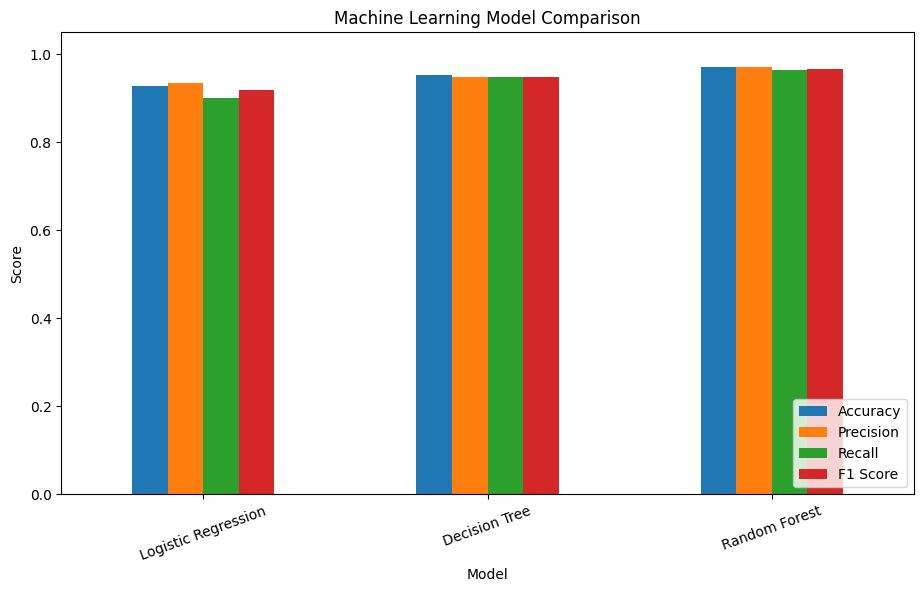

In [ ]:
comparison_df.set_index("Model")[
    ["Accuracy", "Precision", "Recall", "F1 Score"]
].plot(
    kind="bar",
    figsize=(11, 6)
)

plt.title("Machine Learning Model Comparison")

plt.ylabel("Score")

plt.ylim(0, 1.05)

plt.xticks(rotation=20)

plt.legend(loc="lower right")

plt.show()

Confusion matrices

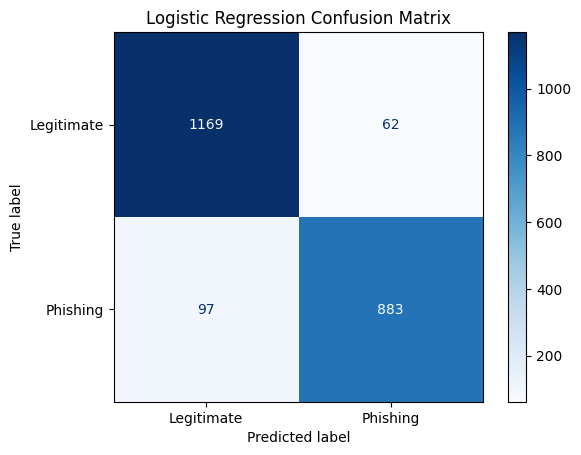

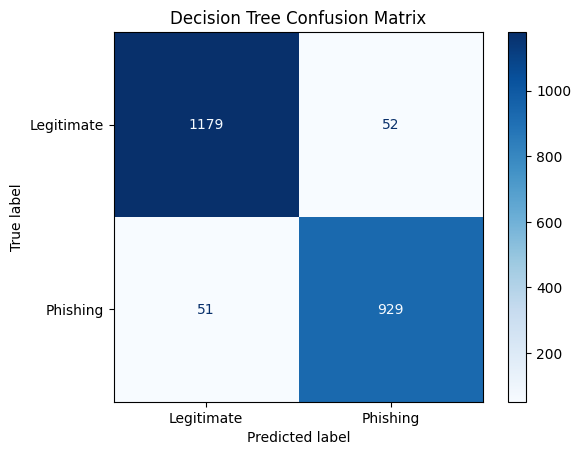

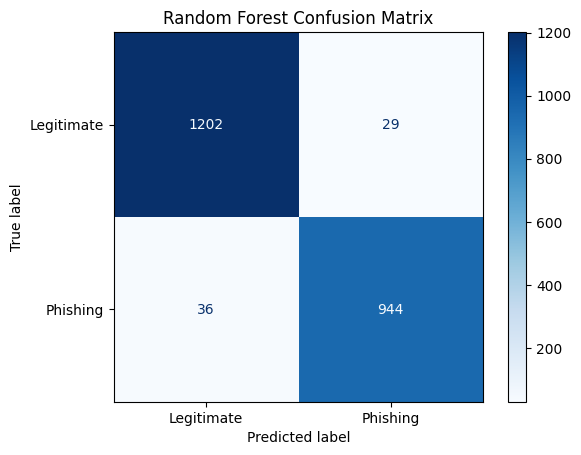

In [ ]:
for name, model in models.items():

    y_pred = model.predict(X_test)

    cm = confusion_matrix(
        y_test,
        y_pred,
        labels=[0, 1]
    )

    display_obj = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["Legitimate", "Phishing"]
    )

    display_obj.plot(cmap="Blues")

    plt.title(name + " Confusion Matrix")

    plt.show()

Generate classification reports

In [ ]:
for name, model in models.items():

    print("\n", "=" * 50)

    print(name)

    print("=" * 50)

    y_pred = model.predict(X_test)

    print(
        classification_report(
            y_test,
            y_pred,
            target_names=[
                "Legitimate",
                "Phishing"
            ],
            zero_division=0
        )
    )


Logistic Regression
              precision    recall  f1-score   support

  Legitimate       0.92      0.95      0.94      1231
    Phishing       0.93      0.90      0.92       980

    accuracy                           0.93      2211
   macro avg       0.93      0.93      0.93      2211
weighted avg       0.93      0.93      0.93      2211


Decision Tree
              precision    recall  f1-score   support

  Legitimate       0.96      0.96      0.96      1231
    Phishing       0.95      0.95      0.95       980

    accuracy                           0.95      2211
   macro avg       0.95      0.95      0.95      2211
weighted avg       0.95      0.95      0.95      2211


Random Forest
              precision    recall  f1-score   support

  Legitimate       0.97      0.98      0.97      1231
    Phishing       0.97      0.96      0.97       980

    accuracy                           0.97      2211
   macro avg       0.97      0.97      0.97      2211
weighted avg       0.97

Cross-validation

In [ ]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

cv_results = []

for name, model in models.items():

    scores = cross_val_score(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring="recall",
        n_jobs=-1
    )

    cv_results.append({
        "Model": name,
        "Fold 1": scores[0],
        "Fold 2": scores[1],
        "Fold 3": scores[2],
        "Fold 4": scores[3],
        "Fold 5": scores[4],
        "Average Recall": scores.mean()
    })

cv_df = pd.DataFrame(cv_results)

print("5-FOLD CROSS-VALIDATION RESULTS")

display(cv_df.round(4))

5-FOLD CROSS-VALIDATION RESULTS


,Model,Fold 1,Fold 2,Fold 3,Fold 4,Fold 5,Average Recall
0,Logistic Regression,0.9133,0.8954,0.9082,0.9119,0.9029,0.9063
1,Decision Tree,0.9439,0.9426,0.9477,0.9349,0.9170,0.9372
2,Random Forest,0.9617,0.9541,0.9617,0.9617,0.9387,0.9556


Hyperparameter tuning

Logistic Regression tuning

In [ ]:
lr_params = {
    "classifier__C": [0.1, 1, 10],
    "classifier__solver": ["liblinear", "lbfgs"]
}

lr_grid = GridSearchCV(
    estimator=lr_model,
    param_grid=lr_params,
    cv=cv,
    scoring="recall",
    n_jobs=-1
)

lr_grid.fit(X_train, y_train)

print("Best Logistic Regression Parameters:")

print(lr_grid.best_params_)

print("Best Cross-validation Recall:")

print(lr_grid.best_score_)

Best Logistic Regression Parameters:
{'classifier__C': 0.1, 'classifier__solver': 'liblinear'}
Best Cross-validation Recall:
0.9068411655850079


Decision Tree tuning

In [ ]:
dt_params = {
    "classifier__max_depth": [None, 5, 10, 20],
    "classifier__min_samples_split": [2, 5, 10],
    "classifier__criterion": ["gini", "entropy"]
}

dt_grid = GridSearchCV(
    estimator=dt_model,
    param_grid=dt_params,
    cv=cv,
    scoring="recall",
    n_jobs=-1
)

dt_grid.fit(X_train, y_train)

print("Best Decision Tree Parameters:")

print(dt_grid.best_params_)

print("Best Cross-validation Recall:")

print(dt_grid.best_score_)

Best Decision Tree Parameters:
{'classifier__criterion': 'entropy', 'classifier__max_depth': None, 'classifier__min_samples_split': 2}
Best Cross-validation Recall:
0.9438452967393853


Random Forest tuning

In [ ]:
rf_params = {
    "classifier__n_estimators": [100, 200],
    "classifier__max_depth": [None, 10, 20],
    "classifier__min_samples_split": [2, 5]
}

rf_grid = GridSearchCV(
    estimator=rf_model,
    param_grid=rf_params,
    cv=cv,
    scoring="recall",
    n_jobs=-1
)

rf_grid.fit(X_train, y_train)

print("Best Random Forest Parameters:")

print(rf_grid.best_params_)

print("Best Cross-validation Recall:")

print(rf_grid.best_score_)

Best Random Forest Parameters:
{'classifier__max_depth': 20, 'classifier__min_samples_split': 2, 'classifier__n_estimators': 100}
Best Cross-validation Recall:
0.9573712435165638


Best model selection

In [ ]:
tuned_models = {
    "Logistic Regression": lr_grid,
    "Decision Tree": dt_grid,
    "Random Forest": rf_grid
}

tuned_results = []

for name, grid in tuned_models.items():

    tuned_results.append({
        "Model": name,
        "Best CV Recall": grid.best_score_,
        "Best Parameters": str(grid.best_params_)
    })

tuned_comparison = pd.DataFrame(tuned_results)

print("TUNED MODEL COMPARISON")

display(tuned_comparison)

# Select model with highest CV recall
best_name = max(
    tuned_models,
    key=lambda name: tuned_models[name].best_score_)

best_model = tuned_models[best_name].best_estimator_

print("\nSelected Best Model:", best_name)

TUNED MODEL COMPARISON


,Model,Best CV Recall,Best Parameters
0,Logistic Regression,0.906841,"{'classifier__C': 0.1, 'classifier__solver': '..."
1,Decision Tree,0.943845,"{'classifier__criterion': 'entropy', 'classifi..."
2,Random Forest,0.957371,"{'classifier__max_depth': 20, 'classifier__min..."



Selected Best Model: Random Forest


Evaluate selected model

In [ ]:
final_predictions = best_model.predict(X_test)

print("FINAL SELECTED MODEL:", best_name)

print("\nAccuracy:",
      accuracy_score(y_test, final_predictions))

print("\nPrecision:",
      precision_score(y_test, final_predictions))

print("\nRecall:",
      recall_score(y_test, final_predictions))

print("\nF1 Score:",
      f1_score(y_test, final_predictions))

print("\nClassification Report:")

print(
    classification_report(
        y_test,
        final_predictions,
        target_names=["Legitimate", "Phishing"]
    )
)

FINAL SELECTED MODEL: Random Forest

Accuracy: 0.9742198100407056

Precision: 0.9762641898864809

Recall: 0.9653061224489796

F1 Score: 0.9707542329399692

Classification Report:
              precision    recall  f1-score   support

  Legitimate       0.97      0.98      0.98      1231
    Phishing       0.98      0.97      0.97       980

    accuracy                           0.97      2211
   macro avg       0.97      0.97      0.97      2211
weighted avg       0.97      0.97      0.97      2211



Final confusion matrix

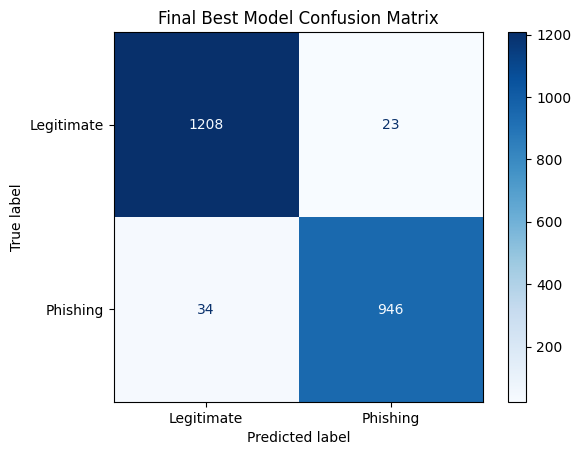

In [ ]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    final_predictions,
    display_labels=["Legitimate", "Phishing"],
    cmap="Blues"
)

plt.title("Final Best Model Confusion Matrix")

plt.show()

Save model

In [ ]:
model_data = {
    "model": best_model,
    "feature_columns": X.columns.tolist(),
    "best_model_name": best_name
}

joblib.dump(
    model_data,
    "phishing_detection_model.pkl"
)

print("Model saved successfully!")

Model saved successfully!


Download saved model

In [ ]:
from google.colab import files

files.download("phishing_detection_model.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import pandas as pd

# Create dummy features matching 31 expected columns (including index as the first column)
new_data = pd.DataFrame([
    [1, -1, 1, 1, 0, 1] + [0] * 25,
    [2, 1, -1, 0, 1, -1] + [1] * 25
])

new_data.to_csv("new_website_data.csv", index=False)

print("New website data saved with 31 columns!")

New website data saved with 31 columns!


In [ ]:
import joblib
import pandas as pd

# Load saved Random Forest model dictionary
model_data = joblib.load("phishing_detection_model.pkl")
model = model_data["model"]
feature_columns = model_data["feature_columns"]

print("Model loaded successfully!")

# Load new website data
new_data = pd.read_csv("new_website_data.csv")

# Map the column names expected by the model
if len(new_data.columns) == len(feature_columns):
    new_data.columns = feature_columns
else:
    print(f"Warning: new_data has {len(new_data.columns)} columns, but the model expects {len(feature_columns)} columns.")

# Predict
predictions = model.predict(new_data)

# Display results
for i, prediction in enumerate(predictions):

    if prediction == 1:
        result = "Phishing Website"

    elif prediction == 0:
        result = "Legitimate Website"

    else:
        result = f"Unknown label: {prediction}"

    print(f"Website {i+1}: {result}")

# Save prediction results
new_data["Prediction"] = predictions

new_data.to_csv("prediction_results.csv", index=False)

print("Prediction completed!")
print("Results saved in prediction_results.csv")

Model loaded successfully!
Website 1: Phishing Website
Website 2: Legitimate Website
Prediction completed!
Results saved in prediction_results.csv
